### 0. Wstęp:
 W moim doświadczeniu zdecydowałam się wziąć dataset, z różnymi parametrami dotycząycmi rodzynek i bedę chciała je zakfalifikować do dwóch grup: Kecimen oraz Besni.

### 1. Przygotowanie danych

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator

df = pd.read_excel("Raisin_Dataset.xlsx")
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


Sprawdźmy, czy nie ma pustych wartości.

In [87]:
print("Brakujące wartości:")
print(df.isnull().sum())

Brakujące wartości:
Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
Extent             0
Perimeter          0
Class              0
dtype: int64


Zobaczmy rozłożenie klas.

In [88]:
print("Liczba rodzynek każdej odmiany:")
print(df["Class"].value_counts())

Liczba rodzynek każdej odmiany:
Class
Kecimen    450
Besni      450
Name: count, dtype: int64


Klasy są równo zbalansowane :)

### 2.Dzielimy dane na treningowe i testowe

In [89]:
X = df.drop(columns=["Class"])
y = df["Class"].map({"Kecimen": 0, "Besni": 1})

# test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# trening i walidacja
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 630
Validation: 135
Test: 135


### 3. Wybieramy cechy

Mamy 7 cech, a w eksperymencie wykorzystamy 5 kubitów, więc wybierzemy 5 cech na podstawie korelacji w zbiorze treningowym.

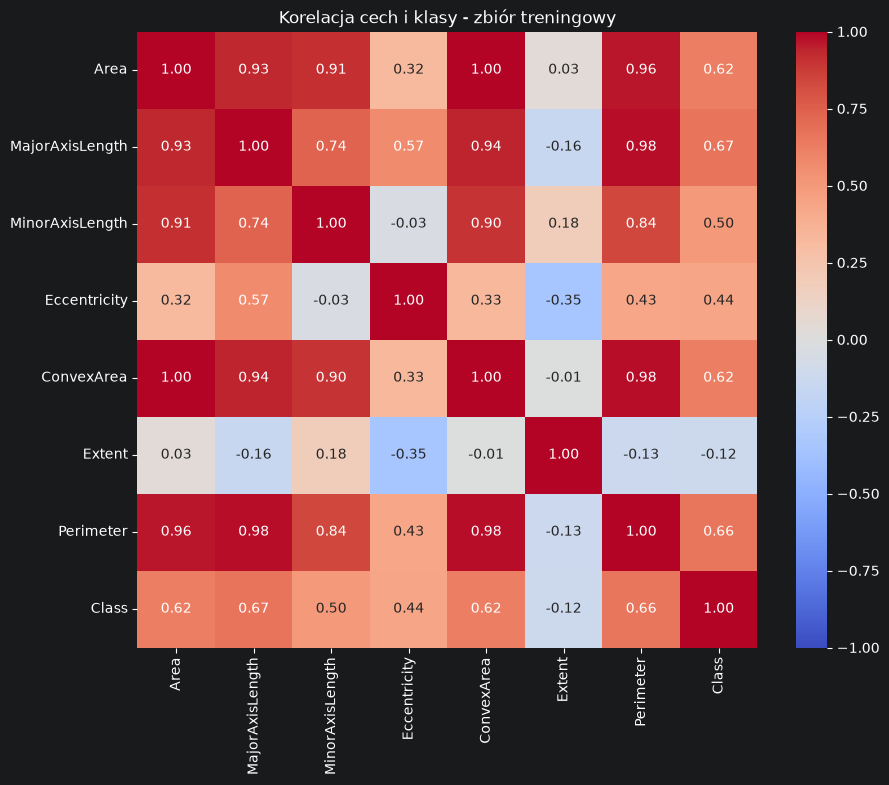

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns

train_corr = X_train.copy()
train_corr["Class"] = y_train

plt.figure(figsize=(10, 8))

sns.heatmap(
    train_corr.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Korelacja cech i klasy - zbiór treningowy")
plt.show()


Zauważmy, że Area i ConvexArea mają korelację bliską 1, więc dla naszego modelu możemy wziąć pod uwagę tylko Area. Podobnie Perimeter i MajorAxisLength mają korelację ok 0.98, więc do modelu weźmiemy tylko MajorAxisLength.
Usuńmy teraz niepotrzebne kolumny.

### 4. Skalujemy wybrane cechy do przedziału od 0 do pi

In [91]:
selected_features = [
    "Area", "MajorAxisLength", "MinorAxisLength",
    "Eccentricity", "Extent"
]

scaler = MinMaxScaler(feature_range=(0, np.pi))

X_train_scaled = scaler.fit_transform(X_train[selected_features])
X_val_scaled = scaler.transform(X_val[selected_features])
X_test_scaled = scaler.transform(X_test[selected_features])

y_train_np = y_train.to_numpy()
y_val_np = y_val.to_numpy()
y_test_np = y_test.to_numpy()


### 5. Encoding Ry i Ansatz

Porównuję dwa encodingi, zachowując identyczny ansatz: rotacje RY, splątanie CX, ponownie rotacje RY

In [92]:
n_qubits = len(selected_features)
x = ParameterVector("x", n_qubits)
th = ParameterVector("t", 2 * n_qubits)

def build_circuit(encoding):
    qc = QuantumCircuit(n_qubits)

    # 01 ENCODING — jedyna różnica między modelami
    for i in range(n_qubits):
        qc.ry(x[i], i)
        if encoding == "RY_RZ":
            qc.rz(x[i], i)

    qc.barrier()

    # 02 ANSATZ — jak na wykładzie: RY, CX, RY
    for i in range(n_qubits):
        qc.ry(th[i], i)

    for i in range(n_qubits - 1):
        qc.cx(i, i + 1)

    for i in range(n_qubits):
        qc.ry(th[n_qubits + i], i)

    return qc

### 6. Tworzymy oba modele

Encoding RY


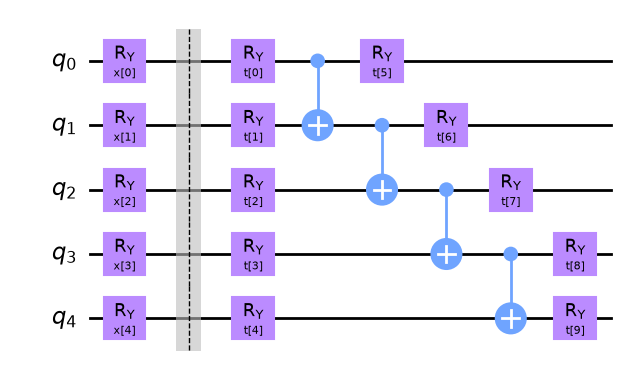

Encoding RY + RZ


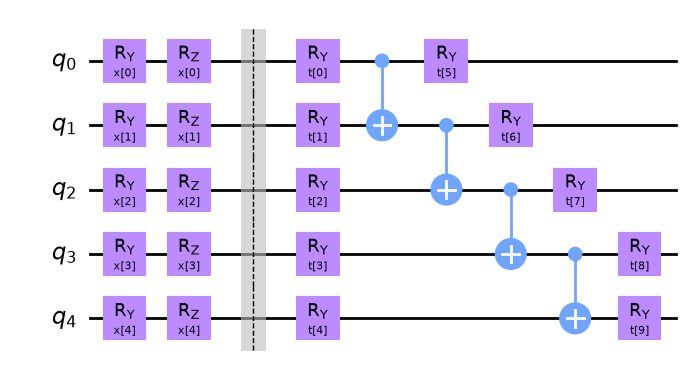

In [93]:
qc_ry = build_circuit("RY")
qc_ry_rz = build_circuit("RY_RZ")

for title, circuit in [("Encoding RY", qc_ry), ("Encoding RY + RZ", qc_ry_rz)]:
    print(title)
    display(circuit.draw(output="mpl", style="clifford", fold=-1))

In [94]:
# 03 OBSERVABLE — Z na pierwszym kubicie
Z0 = SparsePauliOp.from_sparse_list([("Z", [0], 1.0)], num_qubits=n_qubits)
estimator = StatevectorEstimator()

### 7. Funkcja licząca wynik dla jednej rodzynki

In [95]:
def f(qc, x_val, th_val):
    bound = qc.assign_parameters({
        **dict(zip(x, x_val)),
        **dict(zip(th, th_val))
    })
    job = estimator.run([(bound, Z0)])
    return float(job.result()[0].data.evs)

In [96]:
rng = np.random.default_rng(42)
theta_initial = rng.uniform(-0.1, 0.1, len(th))
print("Wynik przykładowej rodzynki:", f(qc_ry, X_train_scaled[0], theta_initial))

Wynik przykładowej rodzynki: 0.6554750138780032


### 8. Trenujemy model

In [97]:

train_limit = None
train_X = X_train_scaled if train_limit is None else X_train_scaled[:train_limit]
train_y = y_train_np if train_limit is None else y_train_np[:train_limit]

def loss(theta, circuit):
    predictions = np.array([f(circuit, row, theta) for row in train_X])
    targets = 1 - 2 * train_y  # 0 - +1, 1 -> -1
    return np.mean((predictions - targets) ** 2)

# Ten sam punkt startowy i optymalizator dla obu modeli
maxiter = 200
result_ry = minimize(loss, theta_initial.copy(), args=(qc_ry,), method="COBYLA",
                     options={"maxiter": maxiter})
result_ry_rz = minimize(loss, theta_initial.copy(), args=(qc_ry_rz,), method="COBYLA",
                        options={"maxiter": maxiter})
print("MSE RY:", result_ry.fun)
print("MSE RY + RZ:", result_ry_rz.fun)

MSE RY: 0.5339575254164024
MSE RY + RZ: 0.775509804156959


### 9. Oceniamy metryki na zbiorze walidacyjnym

Accuracy RY:      0.837
Accuracy RY + RZ: 0.622
Różnica:         -0.215


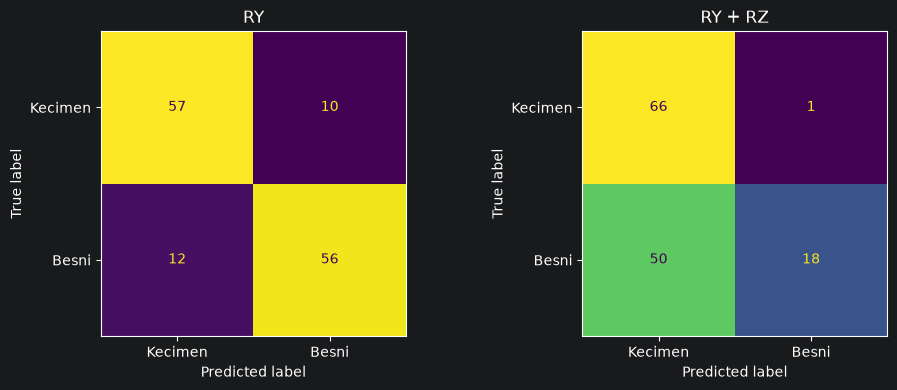

In [102]:
def predict(circuit, theta, X_data):
    return np.array([int(f(circuit, row, theta) < 0) for row in X_data])

pred_ry = predict(qc_ry, result_ry.x, X_val_scaled)
pred_ry_rz = predict(qc_ry_rz, result_ry_rz.x, X_val_scaled)

acc_ry = accuracy_score(y_val_np, pred_ry)
acc_ry_rz = accuracy_score(y_val_np, pred_ry_rz)

print(f"Accuracy RY:      {acc_ry:.3f}")
print(f"Accuracy RY + RZ: {acc_ry_rz:.3f}")
print(f"Różnica:         {acc_ry_rz - acc_ry:+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, preds, title in [
    (axes[0], pred_ry, "RY"),
    (axes[1], pred_ry_rz, "RY + RZ")
]:
    ConfusionMatrixDisplay.from_predictions(
        y_val_np, preds,
        display_labels=["Kecimen", "Besni"],
        ax=ax,
        colorbar=False
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

### 9. Analiza rozkładów na zbiorze walidacyjnym

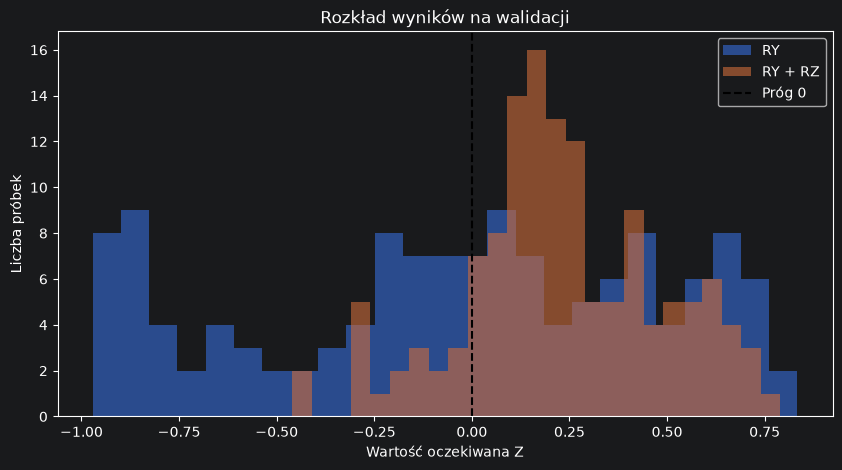

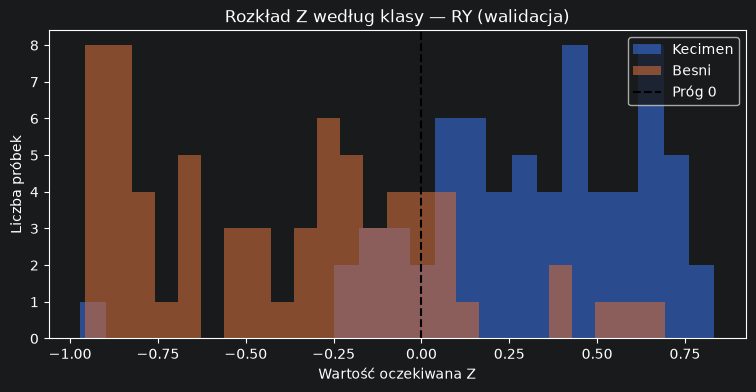

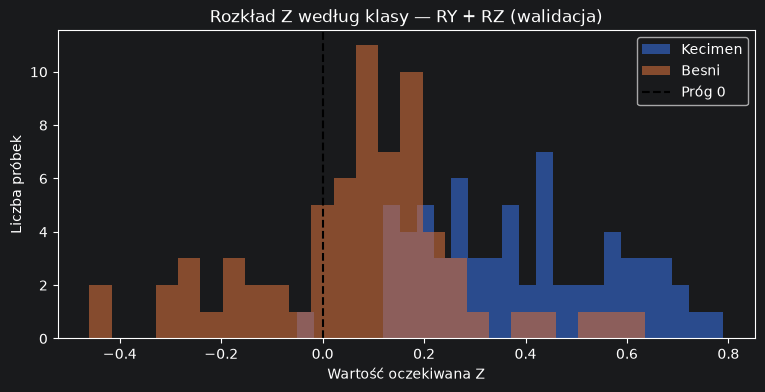

In [99]:
values_ry_val = np.array([f(qc_ry, row, result_ry.x) for row in X_val_scaled])
values_ry_rz_val = np.array([f(qc_ry_rz, row, result_ry_rz.x) for row in X_val_scaled])

plt.figure(figsize=(10, 5))
plt.hist(values_ry_val, bins=25, alpha=0.6, label="RY")
plt.hist(values_ry_rz_val, bins=25, alpha=0.6, label="RY + RZ")
plt.axvline(0, color="black", linestyle="--", label="Próg 0")
plt.xlabel("Wartość oczekiwana Z")
plt.ylabel("Liczba próbek")
plt.title("Rozkład wyników na walidacji")
plt.legend()
plt.show()

for values, name in [(values_ry_val, "RY"), (values_ry_rz_val, "RY + RZ")]:
    plt.figure(figsize=(9, 4))
    plt.hist(values[y_val_np == 0], bins=25, alpha=0.6, label="Kecimen")
    plt.hist(values[y_val_np == 1], bins=25, alpha=0.6, label="Besni")
    plt.axvline(0, color="black", linestyle="--", label="Próg 0")
    plt.title(f"Rozkład Z według klasy — {name} (walidacja)")
    plt.xlabel("Wartość oczekiwana Z")
    plt.ylabel("Liczba próbek")
    plt.legend()
    plt.show()

Metryki dla zbioru walidacyjnego wyszły fatalne przy użyciu Ry i Rz - dużo gorsze niż dla samego Ry. Zaczełam się zastanawiać czemu te wyniki wyszły aż tak różne. W tym celu stworzyłam wykres, pokazujący jak te dwa modele przyporządkowywały różne klasy. Co bardzo ciekawe Model wykorzyszujący Ry i Rz duuuużo większą część wyników przyporządkowywał do klasy 1. Więc pytanie: czemu?
Na kolejnych wykresach osobno widać jak każdy z modeli sobie poradził z kategoryzowaniem. Model Ry i Rz nie kategoryzował danych bardzo niepoprawnie. Problem stanowił próg w 0.0. Z wykresu można odczytać, że zdecydownaie lepsze wyniki osiągałby dla progu ok. 0.2.
W takim razie warto sprawdzić jak zmieniłoby sie accuracy dla najlepiej ustawionego progu

### 10. Ustawienie najlepszego progu

RY:      próg 0: 83.70% | próg dobrany: 0.055 | accuracy: 85.93% | AUC: 0.905
RY + RZ: próg 0: 62.22% | próg dobrany: 0.205 | accuracy: 83.70% | AUC: 0.888


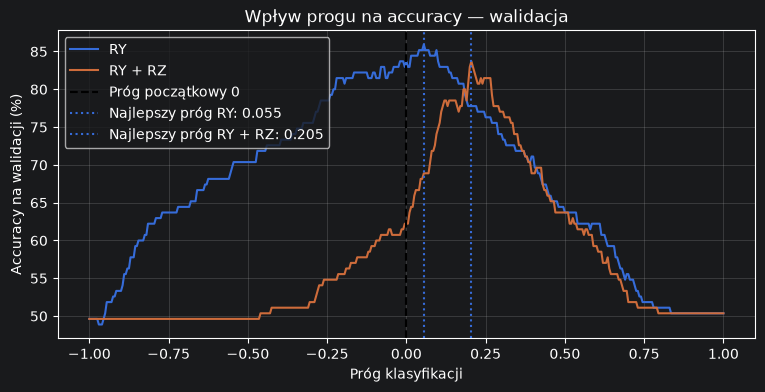

In [100]:
from sklearn.metrics import roc_auc_score

thresholds = np.linspace(-1, 1, 401)

def evaluate_thresholds(values, labels):
    accuracies = np.array([
        accuracy_score(labels, (values < t).astype(int))
        for t in thresholds
    ])
    best_idx = int(np.argmax(accuracies))
    return thresholds[best_idx], accuracies, roc_auc_score(labels, -values)

threshold_ry, accuracies_ry, auc_ry = evaluate_thresholds(values_ry_val, y_val_np)
threshold_ry_rz, accuracies_ry_rz, auc_ry_rz = evaluate_thresholds(values_ry_rz_val, y_val_np)

val_acc_ry_0 = accuracy_score(y_val_np, (values_ry_val < 0).astype(int))
val_acc_ry_rz_0 = accuracy_score(y_val_np, (values_ry_rz_val < 0).astype(int))

print(f"RY:      próg 0: {val_acc_ry_0:.2%} | próg dobrany: {threshold_ry:.3f} | accuracy: {accuracies_ry.max():.2%} | AUC: {auc_ry:.3f}")
print(f"RY + RZ: próg 0: {val_acc_ry_rz_0:.2%} | próg dobrany: {threshold_ry_rz:.3f} | accuracy: {accuracies_ry_rz.max():.2%} | AUC: {auc_ry_rz:.3f}")

plt.figure(figsize=(9, 4))
plt.plot(thresholds, accuracies_ry * 100, label="RY")
plt.plot(thresholds, accuracies_ry_rz * 100, label="RY + RZ")
plt.axvline(0, color="black", linestyle="--", label="Próg początkowy 0")
plt.axvline(threshold_ry, linestyle=":", label=f"Najlepszy próg RY: {threshold_ry:.3f}")
plt.axvline(threshold_ry_rz, linestyle=":", label=f"Najlepszy próg RY + RZ: {threshold_ry_rz:.3f}")
plt.xlabel("Próg klasyfikacji")
plt.ylabel("Accuracy na walidacji (%)")
plt.title("Wpływ progu na accuracy — walidacja")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 11. Końcowa ocena na zbiorze testowym

In [101]:
# Wyniki modeli na zbiorze testowym
values_ry_test = np.array([
    f(qc_ry, row, result_ry.x) for row in X_test_scaled
])

values_ry_rz_test = np.array([
    f(qc_ry_rz, row, result_ry_rz.x) for row in X_test_scaled
])

# Klasyfikacja z progami dobranymi na walidacji
pred_ry_test = (values_ry_test < threshold_ry).astype(int)
pred_ry_rz_test = (values_ry_rz_test < threshold_ry_rz).astype(int)

# Końcowe accuracy
print("RY:", accuracy_score(y_test_np, pred_ry_test))
print("RY + RZ:", accuracy_score(y_test_np, pred_ry_rz_test))

RY: 0.8740740740740741
RY + RZ: 0.8592592592592593
